# 05 · Eventos: ¿cambia el aire en los días de paro?

**Pregunta del TP.** ¿Cambia la contaminación del aire en la Ciudad en los días de paro de colectivos, trenes o
subte?

**Hipótesis.**
- **H1.** En los días de paro de colectivos, el NOx es menor que en días hábiles comparables.
- **H2.** En los días de paro de trenes o subte (con colectivos funcionando), el NOx no baja, porque más gente
  usa el colectivo y el auto.

**Por qué no son obvias.** En Europa, los paros de transporte público **empeoran** el aire: la gente se pasa al
auto (Bauernschuster y otros, 2017; Basagaña y otros, 2018). En Barcelona, con paro de colectivos, el NOx no
cambió y el CO subió 12% (González y otros, 2021). Acá la flota de colectivos es casi toda diésel, el combustible
que más NOx emite: si paran, la predicción se invierte.

**Método, en tres pasos:**
1. **Modelo de un día normal.** Con los ~520 días hábiles normales que tienen datos del SMN se ajusta una
   regresión lineal (OLS) que explica el logaritmo de cada contaminante con el viento, la temperatura, la lluvia,
   la estación de monitoreo, el mes, el año y el día de la semana. No es *machine learning*: es una forma ordenada
   de decir "un jueves de mayo con 8 km/h de viento, en La Boca, suele tener tanto NOx".
2. **Desvío del evento.** Cada paro se compara contra lo que el modelo esperaba para ese día. Como se trabaja en
   logaritmos, el desvío se lee en **porcentaje**.
3. **Prueba placebo.** ¿Un desvío así es raro? Se compara con los desvíos de días normales sorteados al azar.

Variables: **NOx** (lo que sale del caño de escape, la hipótesis), **NO2** (la parte del NOx que daña la salud
respiratoria) y **CO** (que viene sobre todo de los autos a nafta, para entender el mecanismo). Ventana: bloque de
8 a 16 h.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "trenes_subte": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


In [2]:
import statsmodels.formula.api as smf

def fmt_p(p, repeticiones=5000):
    """Valor p de la prueba placebo: con 5.000 sorteos, 0 significa menor que 1/5.000."""
    return f"< {1 / repeticiones:.4f}" if p == 0 else f"{p:.4f}"

d["lluvia"] = d["hubo_lluvia"].astype(float)
# Con viento casi nulo el logaritmo explota: se fija un piso de 2 km/h.
d["log_viento"] = np.log(np.maximum(d["viento_kmh"], 2))

METEO = ["viento_kmh", "temp_c", "lluvia"]
FORMULA = "~ log_viento + temp_c + lluvia + C(estacion) + C(mes) + C(anio) + C(dia_semana)"
VARIABLES = {"nox_816_ppb": "NOx", "no2_816_ppb": "NO2", "co_816_ppm": "CO"}
GRUPOS = {"sin_colectivos": "Paro de colectivos", "trenes_subte": "Paro de trenes o subte"}

normales = d[d.es_dia_normal & d.grupo_evento.isna()].dropna(subset=METEO)
ev = d[d.grupo_evento.notna()].dropna(subset=METEO)
print(f"Días normales con meteorología: {normales.fecha.nunique()} ({len(normales)} estación-día)")
for g, nombre in GRUPOS.items():
    sub = ev[ev.grupo_evento == g]
    print(f"{nombre}: {sub.fecha.nunique()} días ({len(sub)} estación-día): "
          + ", ".join(sorted(sub.fecha.dt.strftime('%d/%m/%Y').unique())))

Días normales con meteorología: 517 (1539 estación-día)
Paro de colectivos: 4 días (12 estación-día): 06/05/2025, 09/05/2024, 11/04/2024, 19/02/2026
Paro de trenes o subte: 3 días (9 estación-día): 10/04/2025, 21/02/2024, 30/10/2024


## 1. El modelo de un día normal

Para saber qué tan bien predice el modelo se usa **validación cruzada** (10 partes): cada día normal se predice
con un modelo que no lo vio. Así sus desvíos son comparables con los de los paros, que tampoco participan del
ajuste.

In [3]:
def ajustar(col, base=normales, eventos=ev, partes=10, semilla=1):
    """Ajusta el modelo, calcula desvíos fuera de muestra de los días normales y desvíos de los eventos."""
    n = base[base[col] > 0].copy()
    n["y"] = np.log(n[col])
    modelo = smf.ols("y " + FORMULA, n).fit()
    grupo = np.random.default_rng(semilla).permutation(len(n)) % partes
    n["desvio"] = np.nan
    for k in range(partes):
        m_k = smf.ols("y " + FORMULA, n[grupo != k]).fit()
        prueba = n.index[grupo == k]
        n.loc[prueba, "desvio"] = n.loc[prueba, "y"] - m_k.predict(n.loc[prueba])
    e = eventos[eventos[col] > 0].copy()
    e["observado"] = e[col]
    e["esperado"] = np.exp(modelo.predict(e))
    e["desvio"] = np.log(e[col]) - np.log(e["esperado"])
    # Percentil placebo: qué % de los días normales de esa estación tuvo un desvío menor.
    e["percentil"] = [(n.loc[n.estacion == s, "desvio"] < r).mean() * 100 for s, r in zip(e.estacion, e.desvio)]
    return modelo, n, e

modelos, normales_res, eventos_res = {}, {}, {}
resumen = []
for col, nombre in VARIABLES.items():
    m, n, e = ajustar(col)
    modelos[nombre], normales_res[nombre], eventos_res[nombre] = m, n, e
    resumen.append({"variable": nombre, "días-estación": int(m.nobs), "R²": m.rsquared,
                    "R² validación cruzada": 1 - n.desvio.var() / n.y.var(),
                    "viento ×2 (%)": (2 ** m.params["log_viento"] - 1) * 100,
                    "+1 °C (%)": (np.exp(m.params["temp_c"]) - 1) * 100,
                    "lluvia (%)": (np.exp(m.params["lluvia"]) - 1) * 100})
pd.DataFrame(resumen).set_index("variable").round(2)

,días-estación,R²,R² validación cruzada,viento ×2 (%),+1 °C (%),lluvia (%)
variable,,,,,,
NOx,1242,0.46,0.44,-29.72,-0.07,4.48
NO2,1242,0.57,0.55,-23.27,1.00,5.19
CO,1409,0.47,0.45,-23.19,1.38,5.48


**Cómo se lee.** "viento ×2" es cuánto cambia el contaminante si el viento se duplica, con todo lo demás igual.
El modelo explica cerca de la mitad de la variación diaria, y el R² de validación cruzada es parecido al del
ajuste: no hay sobreajuste. El viento es, lejos, el factor meteorológico que más pesa.

## 2. Cada paro contra su día esperado

La franja gris es el rango donde cae el 90% de los días normales (percentiles 5 a 95). Un punto a la izquierda
de la franja es una caída que solo tiene el 5% de los días normales; a la derecha, una suba igual de rara.

In [4]:
filas = []
for nombre, e in eventos_res.items():
    for _, r in e.iterrows():
        filas.append({"fecha": r.fecha, "evento": r.evento, "grupo": r.grupo_evento, "estacion": r.estacion,
                      "variable": nombre, "observado": r.observado, "esperado": r.esperado,
                      "desvio_pct": (np.exp(r.desvio) - 1) * 100, "percentil_placebo": r.percentil,
                      "viento_kmh": r.viento_kmh, "lluvia_mm": r.precipitacion_mm})
resultados = pd.DataFrame(filas)
tabla = resultados.pivot_table(index=["grupo", "fecha", "estacion"], columns="variable",
                               values=["desvio_pct", "percentil_placebo"])
tabla.reindex(columns=list(VARIABLES.values()), level=1).round(0)

desvio_pct                \
variable                                    NOx    NO2     CO   
grupo          fecha      estacion                              
sin_colectivos 2024-04-11 CENTENARIO        NaN    NaN -20.00   
                          CORDOBA         25.00  16.00    NaN   
                          LA BOCA        -27.00   7.00  98.00   
               2024-05-09 CENTENARIO        NaN    NaN -25.00   
                          CORDOBA        -15.00  -7.00    NaN   
                          LA BOCA        -48.00 -18.00  38.00   
               2025-05-06 CENTENARIO     -21.00 -19.00 -27.00   
                          CORDOBA        -24.00 -34.00  22.00   
                          LA BOCA         -5.00 -10.00 -10.00   
               2026-02-19 CENTENARIO     -62.00 -56.00  -6.00   
                          CORDOBA         66.00  29.00 110.00   
                          LA BOCA        -74.00 -71.00 -22.00   
trenes_subte   2024-02-21 CORDOBA        -25.00 -45.00 -16.00   
                          LA BOCA          3.00 -25.00  24.00   
               2024-10-30 CENTENARIO        NaN    NaN -29.00   
                          CORDOBA        -12.00 -14.00 -21.00   
                          LA BOCA        -17.00  -1.00  17.00   
               2025-04-10 CENTENARIO     -48.00 -25.00 -17.00   
                          CORDOBA        -23.00 -25.00  11.00   
                          LA BOCA          4.00   0.00 -32.00   

                                     percentil_placebo              
variable                                           NOx   NO2    CO  
grupo          fecha      estacion                                  
sin_colectivos 2024-04-11 CENTENARIO               NaN   NaN 22.00  
                          CORDOBA                68.00 68.00   NaN  
                          LA BOCA                18.00 57.00 98.00  
               2024-05-09 CENTENARIO               NaN   NaN 16.00  
                          CORDOBA                32.00 41.00   NaN  
                          LA BOCA                 8.00 21.00 82.00  
               2025-05-06 CENTENARIO             26.00 17.00 15.00  
                          CORDOBA                25.00 10.00 67.00  
                          LA BOCA                35.00 34.00 39.00  
               2026-02-19 CENTENARIO              0.00  1.00 46.00  
                          CORDOBA                89.00 78.00 99.00  
                          LA BOCA                 0.00  0.00 23.00  
trenes_subte   2024-02-21 CORDOBA                24.00  3.00 29.00  
                          LA BOCA                43.00 14.00 72.00  
               2024-10-30 CENTENARIO               NaN   NaN 13.00  
                          CORDOBA                34.00 31.00 24.00  
                          LA BOCA                25.00 46.00 66.00  
               2025-04-10 CENTENARIO              0.00 10.00 27.00  
                          CORDOBA                27.00 18.00 55.00  
                          LA BOCA                43.00 47.00 13.00

Text(0.01, -0.03, 'Franja gris: 90% central de los días hábiles normales (desvíos fuera de muestra). Sin punto = sin dato publicado ese día.')

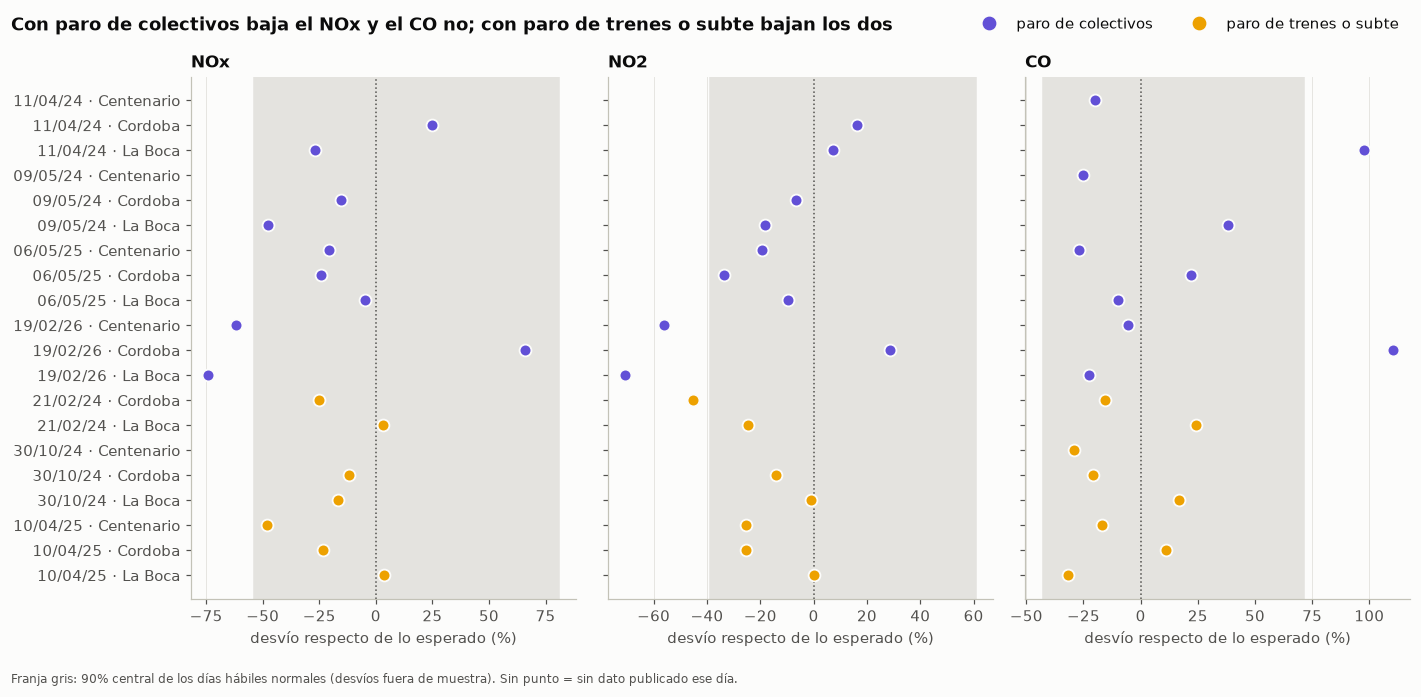

In [5]:
from matplotlib.lines import Line2D
orden = (resultados[["grupo", "fecha", "estacion"]].drop_duplicates()
         .sort_values(["grupo", "fecha", "estacion"]))
claves = list(zip(orden.fecha, orden.estacion))
fig, axes = plt.subplots(1, 3, figsize=(13, 6), sharey=True)
for ax, nombre in zip(axes, VARIABLES.values()):
    n = normales_res[nombre]
    lo, hi = (np.exp(n.desvio.quantile([0.05, 0.95])) - 1) * 100
    ax.axvspan(lo, hi, color="#e4e3df", zorder=0)
    ax.axvline(0, color=TINTA_2, lw=1, ls=":")
    sub = resultados[resultados.variable == nombre].set_index(["fecha", "estacion"])
    for i, k in enumerate(claves[::-1]):
        if k in sub.index:
            r = sub.loc[k]
            ax.scatter(r.desvio_pct, i, s=60, color=COLOR_EVENTO[r.grupo], edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
    ax.set_title(nombre)
    ax.set_xlabel("desvío respecto de lo esperado (%)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(claves)), [f"{f:%d/%m/%y} · {e.title()}" for f, e in claves[::-1]])
marcas = [Line2D([], [], marker="o", ls="", markersize=8, color=COLOR_EVENTO[g], label=GRUPOS[g].lower())
          for g in GRUPOS]
fig.suptitle("Con paro de colectivos baja el NOx y el CO no; con paro de trenes o subte bajan los dos", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()
fig.legend(handles=marcas, loc="upper right", bbox_to_anchor=(0.99, 1.0), ncol=2)
fig.text(0.01, -0.03, "Franja gris: 90% central de los días hábiles normales (desvíos fuera de muestra). "
         "Sin punto = sin dato publicado ese día.", fontsize=8, color=TINTA_2)

## 3. Prueba placebo: ¿los paros se distinguen de días normales al azar?

Un paro aislado puede caer en el extremo por casualidad. La pregunta fuerte es: **si se eligen al azar días
normales, ¿qué tan seguido tienen, en promedio, un desvío como el de los paros?** Se sortean días normales
completos (con las mismas estaciones que tenían dato en cada paro, porque las estaciones de un mismo día se
parecen) y se repite 5.000 veces.

**Cómo leer el valor p.** No es "la probabilidad de que la hipótesis sea cierta". Responde: *si los días de paro
fueran días comunes, ¿con qué frecuencia veríamos por casualidad un desvío así?*
- p = 0,20 → pasa en 1 de cada 5 sorteos: es un desvío habitual.
- p = 0,002 → pasa en 2 de cada 1.000 sorteos: muy difícil de explicar por casualidad.
- p < 0,0002 → no pasó en ninguno de los 5.000 sorteos.

Por convención, por debajo de 0,05 se dice "estadísticamente significativo". Un p chico dice que el desvío es
raro, **no qué lo causó**. Se calculan dos: la probabilidad de una **caída** tan grande (para H1) y la de una
**suba** tan grande (para ver si los paros de trenes o subte empeoran el aire, como en Europa).

In [6]:
def placebo_grupo(nombre, grupo, eventos=None, repeticiones=5000, semilla=0):
    """Devuelve el desvío medio del grupo, los sorteos y los valores p de caída y de suba."""
    e = eventos_res[nombre] if eventos is None else eventos
    e = e[e.grupo_evento == grupo]
    observado = e.desvio.mean()
    tabla_dias = normales_res[nombre].pivot_table(index="fecha", columns="estacion", values="desvio")
    rng = np.random.default_rng(semilla)
    candidatos = {f: tabla_dias[list(sub.estacion)].dropna().values for f, sub in e.groupby("fecha")}
    sims = np.empty(repeticiones)
    for i in range(repeticiones):
        sims[i] = np.concatenate([c[rng.integers(len(c))] for c in candidatos.values()]).mean()
    return observado, sims, (sims <= observado).mean(), (sims >= observado).mean(), len(e), e.fecha.nunique()

grupos, sims_guardadas = [], {}
for nombre in VARIABLES.values():
    for grupo in GRUPOS:
        obs, sims, p_baja, p_sube, n_obs, n_dias = placebo_grupo(nombre, grupo)
        sims_guardadas[(nombre, grupo)] = (obs, sims)
        grupos.append({"variable": nombre, "grupo": grupo, "días": n_dias, "estación-día": n_obs,
                       "desvío medio (%)": (np.exp(obs) - 1) * 100, "p caída": p_baja, "p suba": p_sube})
grupos = pd.DataFrame(grupos)
vista = grupos.assign(**{"desvío medio (%)": grupos["desvío medio (%)"].round(0),
                         "p caída": grupos["p caída"].map(fmt_p), "p suba": grupos["p suba"].map(fmt_p),
                         "grupo": grupos.grupo.map(GRUPOS)})
vista.set_index(["variable", "grupo"])

días  estación-día  desvío medio (%) p caída  \
variable grupo                                                                  
NOx      Paro de colectivos         4            10            -28.00  0.0016   
         Paro de trenes o subte     3             7            -19.00  0.0510   
NO2      Paro de colectivos         4            10            -23.00  0.0068   
         Paro de trenes o subte     3             7            -21.00  0.0258   
CO       Paro de colectivos         4            10              7.00  0.7468   
         Paro de trenes o subte     3             8            -10.00  0.2472   

                                 p suba  
variable grupo                           
NOx      Paro de colectivos      0.9984  
         Paro de trenes o subte  0.9490  
NO2      Paro de colectivos      0.9932  
         Paro de trenes o subte  0.9742  
CO       Paro de colectivos      0.2532  
         Paro de trenes o subte  0.7528

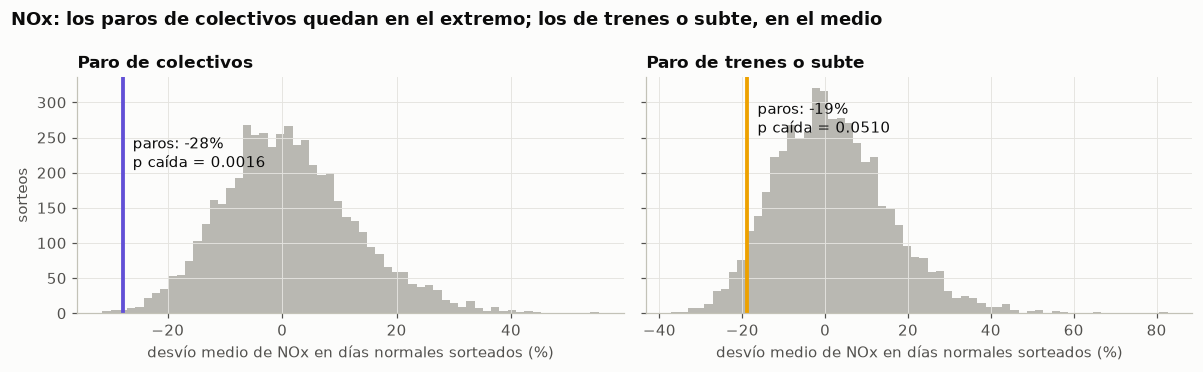

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, grupo in zip(axes, GRUPOS):
    obs, sims = sims_guardadas[("NOx", grupo)]
    ax.hist((np.exp(sims) - 1) * 100, bins=60, color=GRIS)
    ax.axvline((np.exp(obs) - 1) * 100, color=COLOR_EVENTO[grupo], lw=2.5)
    p = (sims <= obs).mean()
    ax.text((np.exp(obs) - 1) * 100, ax.get_ylim()[1] * 0.9,
            f"  paros: {(np.exp(obs) - 1) * 100:.0f}%\n  p caída {fmt_p(p) if p == 0 else '= ' + fmt_p(p)}",
            color=TINTA, va="top")
    ax.set_title(GRUPOS[grupo])
    ax.set_xlabel("desvío medio de NOx en días normales sorteados (%)")
axes[0].set_ylabel("sorteos")
fig.suptitle("NOx: los paros de colectivos quedan en el extremo; los de trenes o subte, en el medio", x=0.01,
             ha="left", fontweight="bold")
plt.tight_layout()

**Lectura.**
- **H1 (paros de colectivos):** el NOx quedó en promedio un **28% por debajo** de lo esperado y solo 16 de cada
  10.000 sorteos de días normales llegan tan abajo (p ≈ 0,002). El NO2 bajó un 23% (p ≈ 0,007). **H1 se sostiene.**
- **H2 (paros de trenes o subte):** la predicción era que el NOx no bajara. **Bajó igual**, un 19% (p ≈ 0,05, en el
  límite) y el NO2 un 21% (p ≈ 0,03). Lo que seguro no pasó es lo de Europa: **en ningún caso el aire empeoró**
  (p de suba de 0,95 a 0,97). **H2 no se sostiene tal como estaba planteada.**
- Una explicación posible: un día de paro, con lo que sea que pare, mucha gente no viaja o trabaja desde su casa,
  y eso baja el tránsito en general. Dos de los tres paros de trenes o subte fueron, además, parte de paros
  generales o de protesta amplia.
- **El CO es lo que separa los dos grupos:** en los paros de colectivos no bajó (+7%), en los de trenes o subte sí
  (−10%). Eso se analiza en la sección 4.

## 4. Verificaciones

**a) ¿La caída del NOx en los paros de colectivos es por el diésel o por "menos actividad en general"?** Si fuera
solo menos actividad, el CO tendría que bajar a la par. Por eso se compara el desvío del NOx con el del CO **en
los mismos casos** (los que tienen los dos datos). La diferencia entre ambos equivale al cociente NOx/CO, que
también se somete a la prueba placebo.

In [8]:
_, nratio, eratio = ajustar("nox_co_816")
normales_res["NOx/CO"], eventos_res["NOx/CO"] = nratio, eratio
desvios = pd.concat([eventos_res[v].assign(variable=v)[["fecha", "estacion", "grupo_evento", "variable", "desvio"]]
                     for v in ["NOx", "CO", "NOx/CO"]])
ancho = desvios.pivot_table(index=["grupo_evento", "fecha", "estacion"], columns="variable", values="desvio").dropna()
filas = []
for grupo, sub in ancho.groupby(level="grupo_evento"):
    m = sub.mean()
    _, _, p_baja, _, _, _ = placebo_grupo("NOx/CO", grupo)
    filas.append({"grupo": GRUPOS[grupo], "estación-día": len(sub), "NOx (%)": (np.exp(m["NOx"]) - 1) * 100,
                  "CO (%)": (np.exp(m["CO"]) - 1) * 100, "NOx relativo al CO (%)": (np.exp(m["NOx/CO"]) - 1) * 100,
                  "p caída (NOx relativo al CO)": fmt_p(p_baja)})
pd.DataFrame(filas).set_index("grupo").round(0)

,estación-día,NOx (%),CO (%),NOx relativo al CO (%),p caída (NOx relativo al CO)
grupo,,,,,
Paro de colectivos,8,-34.00,16.00,-43.00,< 0.0002
Paro de trenes o subte,7,-19.00,-7.00,-10.00,0.1502


**b) ¿Depende de un solo paro?** Se repite la prueba de H1 sacando un paro de colectivos por vez.

In [9]:
filas = []
e_all = eventos_res["NOx"]
for fecha in sorted(e_all.loc[e_all.grupo_evento == "sin_colectivos", "fecha"].unique()):
    obs, _, p, _, n_obs, n_dias = placebo_grupo("NOx", "sin_colectivos", eventos=e_all[e_all.fecha != fecha])
    filas.append({"sin el paro del": f"{pd.Timestamp(fecha):%d/%m/%Y}", "días": n_dias,
                  "desvío medio NOx (%)": round((np.exp(obs) - 1) * 100), "p caída": fmt_p(p)})
pd.DataFrame(filas)

,sin el paro del,días,desvío medio NOx (%),p caída
0,11/04/2024,3,-33,0.0006
1,09/05/2024,3,-26,0.0056
2,06/05/2025,3,-32,0.0018
3,19/02/2026,3,-19,0.0496


**c) ¿Depende de la ventana de 8 a 16 h?** Se repite con el promedio de 24 h de NOx.

In [10]:
_, nn24, en24 = ajustar("nox_24h_ppb")
normales_res["NOx 24 h"], eventos_res["NOx 24 h"] = nn24, en24
filas = []
for grupo in GRUPOS:
    for nombre in ["NOx", "NOx 24 h"]:
        obs, _, p_baja, p_sube, _, _ = placebo_grupo(nombre, grupo)
        filas.append({"grupo": GRUPOS[grupo], "ventana": "8-16 h" if nombre == "NOx" else "24 h",
                      "desvío medio (%)": round((np.exp(obs) - 1) * 100), "p caída": fmt_p(p_baja),
                      "p suba": fmt_p(p_sube)})
pd.DataFrame(filas)

,grupo,ventana,desvío medio (%),p caída,p suba
0,Paro de colectivos,8-16 h,-28,0.0016,0.9984
1,Paro de colectivos,24 h,-32,< 0.0002,1.0000
2,Paro de trenes o subte,8-16 h,-19,0.0510,0.9490
3,Paro de trenes o subte,24 h,-21,0.0202,0.9798


**Lectura de las verificaciones.**
- **a) Diésel o actividad general:** en los mismos casos, en los paros de colectivos el NOx bajó 34% y **el CO subió
  16%**: cae lo que emite el diésel y no lo que emiten los autos (que, si algo, aumentan). En los paros de trenes o
  subte bajaron los dos (NOx −19%, CO −7%): menos tránsito en general, sin cambio en la composición. Medido como
  NOx relativo al CO, la diferencia es clara: −43% (ningún sorteo llega tan abajo) contra −10% (p ≈ 0,15).
  **Esto es lo que permite decir que la caída del NOx en los paros de colectivos tiene que ver con los colectivos.**
- **b) Un solo paro:** sacando cualquiera de los paros de colectivos, el NOx sigue entre 19% y 33% por debajo de
  lo esperado. El resultado más débil es sin el 19/02/2026 (−19%, p ≈ 0,05): ese día pesa mucho.
- **c) Ventana:** con el promedio de 24 h los resultados son prácticamente iguales (−32% y −21%).

## 5. Contexto normativo (comentario final, fuera de las hipótesis)

No es parte de la pregunta: sirve para ubicar los niveles. Hay dos referencias distintas para el NO2:
- **Norma de la Ciudad** (Ley 1356, Res. 68-APRA/21, 3ª etapa, vigente en 2024-2026): promedio anual de
  32 ppb (60 µg/m³) y horario de 106 ppb. No tiene un valor de 24 h.
- **Guía de la OMS (2021)**, una meta de salud, no una obligación legal: 10 µg/m³ anual y 25 µg/m³ en 24 h.

In [11]:
NORMA_CABA_ANUAL = 60              # µg/m³ (32 ppb), Res. 68-APRA/21, 3ª etapa
GUIA_OMS_ANUAL, GUIA_OMS_24H = 10, 25  # µg/m³, OMS 2021
anual = d.groupby(["estacion", "anio"])["no2_24h_ugm3"].agg(["count", "mean"])
anual.columns = ["días con dato", "NO2 media (µg/m³)"]
anual["norma de la Ciudad (60)"] = np.where(anual["NO2 media (µg/m³)"] <= NORMA_CABA_ANUAL, "cumple", "no cumple")
anual["veces la guía OMS (10)"] = anual["NO2 media (µg/m³)"] / GUIA_OMS_ANUAL
paros = d[d.grupo_evento.eq("sin_colectivos")].dropna(subset=["no2_24h_ugm3"])
print(f"Paros de colectivos: {(paros.no2_24h_ugm3 > GUIA_OMS_24H).sum()} de {len(paros)} mediciones con NO2 de 24 h "
      f"sobre la guía OMS de {GUIA_OMS_24H} µg/m³ (mediana: {paros.no2_24h_ugm3.median():.0f} µg/m³).")
print("2026: hasta septiembre. Centenario 2024: pocos días con dato.")
anual.round(1)

Paros de colectivos: 8 de 10 mediciones con NO2 de 24 h sobre la guía OMS de 25 µg/m³ (mediana: 32 µg/m³).
2026: hasta septiembre. Centenario 2024: pocos días con dato.


días con dato  NO2 media (µg/m³) norma de la Ciudad (60)  \
estacion   anio                                                             
CENTENARIO 2024             66              23.30                  cumple   
           2025            322              28.10                  cumple   
           2026            265              25.10                  cumple   
CORDOBA    2024            300              38.90                  cumple   
           2025            320              34.90                  cumple   
           2026            262              36.10                  cumple   
LA BOCA    2024            348              56.30                  cumple   
           2025            358              49.80                  cumple   
           2026            231              46.70                  cumple   

                 veces la guía OMS (10)  
estacion   anio                          
CENTENARIO 2024                    2.30  
           2025                    2.80  
           2026                    2.50  
CORDOBA    2024                    3.90  
           2025                    3.50  
           2026                    3.60  
LA BOCA    2024                    5.60  
           2025                    5.00  
           2026                    4.70

**Lectura.** En promedio anual, las tres estaciones **cumplen la norma de la Ciudad**, pero superan entre 2 y casi 6
veces la **guía anual de la OMS**. Ni siquiera en los paros de colectivos se llega a la guía diaria de la OMS: la
mayoría de las mediciones quedó por encima de 25 µg/m³. El valor horario de la Ciudad (106 ppb) tampoco se superó en
el período (pregunta 2 de `consultas.sql`, que usa los máximos horarios de silver).

## 6. Resultados para el dashboard

Se guardan en `export/` (y `run.py` los pasa a CSV para Looker Studio):
- `resultados_evento.parquet`: una fila por paro, estación y variable (NOx, NO2 y CO).
- `resultados_grupo.parquet`: desvío medio y valores p por grupo y variable.

In [12]:
resultados.to_parquet(BASE / "resultados_evento.parquet", index=False)
(grupos.rename(columns={"días": "dias", "estación-día": "estacion_dia", "desvío medio (%)": "desvio_medio_pct",
                        "p caída": "valor_p", "p suba": "valor_p_suba"})
       .to_parquet(BASE / "resultados_grupo.parquet", index=False))
print(f"Guardado en {BASE}")

Guardado en ../export


## Conclusiones

**Respuesta a la pregunta.** Sí, la contaminación cambia en los días de paro, y **baja**: en ningún paro de
2024-2026 el aire de la Ciudad empeoró, a diferencia de lo que se encontró en ciudades europeas.

**H1, paros de colectivos: se sostiene.** El NOx fue un 28% más bajo de lo esperable para un día con ese clima y
calendario (p ≈ 0,002) y el NO2 un 23% (p ≈ 0,007). Además, el CO no bajó: lo que desaparece es lo que emite el
diésel, no lo que emiten los autos. Es consistente con que salga de la calle la flota de colectivos y parte de la
gente la reemplace con el auto.

**H2, paros de trenes o subte: no se sostiene.** Esperábamos que el NOx no bajara, y bajó un 19% (p ≈ 0,05, en
el límite), aunque menos que con paro de colectivos y junto con el CO. La lectura más simple es que un día de paro
hay menos actividad en general. Lo importante para la pregunta: tampoco acá el aire empeoró.

**Comentario final (contexto normativo):** las tres estaciones cumplen la norma de la Ciudad para el NO2
(Res. 68-APRA/21), pero no la guía de la OMS de 2021, que es mucho más exigente. Ni en los días de paro de
colectivos se llega a la guía: sacar los colectivos baja el NO2, pero no alcanza.

**Evento por evento:**
- **19/02/2026** (paro general, sin colectivos, trenes ni subte): el más claro, con NOx 62-74% por debajo de lo
  esperado en Centenario y La Boca. Córdoba ese día tuvo NOx y CO muy por encima de lo esperado: algo local (más
  autos en la avenida, una fuente puntual) que conviene revisar.
- **11/04/2024 y 09/05/2024:** el NOx bajó en La Boca (−27% y −48%) y el CO subió fuerte (+98% y +38%).
- **06/05/2025** (paro de la UTA con 11 mm de lluvia): caídas moderadas en las tres estaciones.

**Limitaciones (para decirlas en la exposición):**
1. **Pocos eventos:** 4 paros de colectivos y 3 de trenes o subte. Hablamos de evidencia consistente, no de
   demostración. El resultado de H1 se apoya bastante en el 19/02/2026.
2. **Colectivos o camiones:** dos de los paros de colectivos fueron paros generales; si los camiones también
   pararon, parte de la caída del NOx es de ellos.
3. **Los paros no son solo "sin colectivos":** son días con menos actividad en general, como muestra H2.
4. **SUBE mide pasajeros**, no colectivos en la calle ni kilómetros recorridos dentro de la Ciudad.
5. **Meteorología diaria:** el SMN da promedios de 24 h, no de la ventana de 8 a 16 h, y la lluvia es diaria.
6. **Datos públicos redondeados** (NOx en ppb enteros, CO con un decimal) y huecos de la fuente (en 2024 casi todo
   viene de La Boca).
7. **No usamos PM10:** depende sobre todo de polvo y fuentes regionales y no respondió a los paros. El indicador
   indicado para el diésel sería el PM2,5, que no está en los datos públicos usados.